# News headline embedding visualiser

Do sentence embeddings predict the topic of an unseen news headline more accurately than TF-IDF when both use the topic of the most similar training headline?

I use PCA to explore how the two representations arrange the same headlines in two dimensions.

In [1]:
from pathlib import Path

raw_path = Path("data/raw/newsCorpora.csv").resolve()
raw_path.parent.mkdir(parents=True, exist_ok=True)

print("Copy your CSV into this folder:")
print(raw_path.parent)
print("File found:", raw_path.is_file())

Copy your CSV into this folder:
C:\Users\msi\Desktop\embedding-visualiser\data\raw
File found: True


In [2]:
from pathlib import Path
import csv
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.decomposition import PCA
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import accuracy_score, f1_score
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.model_selection import StratifiedKFold, train_test_split

SEED = 42
raw_path = Path("data/raw/newsCorpora.csv")
processed = Path("data/processed")
results = Path("results")
processed.mkdir(parents=True, exist_ok=True)
results.mkdir(exist_ok=True)

columns = ["ID", "TITLE", "URL", "PUBLISHER", "CATEGORY", "STORY", "HOSTNAME", "TIMESTAMP"]
news = pd.read_csv(raw_path, sep="\t", header=None, names=columns,
                   usecols=["TITLE", "CATEGORY", "STORY"], dtype="string",
                   quoting=csv.QUOTE_NONE)
print("Source rows:", len(news))
display(news.head())
display(news.isna().sum())

Source rows: 422937


,TITLE,CATEGORY,STORY
0,"Fed official says weak data caused by weather,...",b,ddUyU0VZz0BRneMioxUPQVP6sIxvM
1,Fed's Charles Plosser sees high bar for change...,b,ddUyU0VZz0BRneMioxUPQVP6sIxvM
2,US open: Stocks fall after Fed official hints ...,b,ddUyU0VZz0BRneMioxUPQVP6sIxvM
3,"Fed risks falling 'behind the curve', Charles ...",b,ddUyU0VZz0BRneMioxUPQVP6sIxvM
4,Fed's Plosser: Nasty Weather Has Curbed Job Gr...,b,ddUyU0VZz0BRneMioxUPQVP6sIxvM


TITLE       0
CATEGORY    0
STORY       0
dtype: int64

## 1. Load the news headlines
Run the notebook from its project folder. The source file is tab-separated and has no header. Keep the title, topic code and story ID.

## 2. Prepare a balanced sample
Remove empty fields and repeated headlines. Shuffle before choosing one headline per story so that publishers appearing first in the file have no special preference. Draw 500 stories per topic.

In [3]:
topics = {"b": "Business", "t": "Science and Technology", "e": "Entertainment", "m": "Health"}
clean = news.dropna().copy()
for column in clean.columns:
    clean[column] = clean[column].str.strip()
clean = clean.loc[clean.ne("").all(axis=1)].copy()
clean["topic"] = clean["CATEGORY"].map(topics)
if clean["topic"].isna().any():
    raise ValueError("Unexpected topic code. Check the file format and CATEGORY column.")

clean["title_key"] = clean["TITLE"].str.casefold().str.replace(r"\s+", " ", regex=True)
unique = (clean.sample(frac=1, random_state=SEED)
          .drop_duplicates("title_key").drop_duplicates("STORY"))
counts = unique["topic"].value_counts().reindex(topics.values(), fill_value=0)
display(counts)
if counts.min() < 500:
    raise ValueError("At least one topic has fewer than 500 usable stories.")

sample = (unique.groupby("topic").sample(n=500, random_state=SEED)
          .sample(frac=1, random_state=SEED).reset_index(drop=True))
sample = sample[["TITLE", "topic", "STORY"]]
sample.to_csv(processed / "headlines_sample.csv", index=False)
display(sample["topic"].value_counts())

topic
Business                  2015
Science and Technology    1789
Entertainment             2075
Health                    1343
Name: count, dtype: int64

topic
Science and Technology    500
Business                  500
Health                    500
Entertainment             500
Name: count, dtype: int64

## 3. Reserve a test set
Use the same split and five training folds for both methods. Stratification keeps each topic equally represented. Each row index refers to one headline throughout the notebook.

In [11]:
titles = sample["TITLE"].to_numpy(dtype=str)
labels = sample["topic"].to_numpy(dtype=str)
train, test = train_test_split(np.arange(len(sample)), test_size=0.2,
                               stratify=labels, random_state=SEED)
splitter = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
folds = [(train[a], train[b]) for a, b in splitter.split(train, labels[train])]
print(f"{len(train)} training headlines and {len(test)} held-out headlines")

1600 training headlines and 400 held-out headlines


## 4. Build the TF-IDF baseline
Fit the vocabulary using only the training headlines in each fold. Cosine similarity compares vectors. Each query borrows the topic of its closest training headline. If scores tie, the first maximum wins.

In [5]:
def tfidf_vectors(reference, query):
    vectorizer = TfidfVectorizer(dtype=np.float32)
    reference_vectors = vectorizer.fit_transform(titles[reference])
    query_vectors = vectorizer.transform(titles[query])
    return reference_vectors, query_vectors

def predict_topics(method, stage, reference, query, reference_vectors, query_vectors):
    similarities = cosine_similarity(query_vectors, reference_vectors)
    positions = similarities.argmax(axis=1)
    neighbours = reference[positions]
    return pd.DataFrame({
        "method": method, "stage": stage, "headline": titles[query],
        "actual": labels[query], "predicted": labels[neighbours],
        "nearest_training_headline": titles[neighbours],
        "similarity": similarities[np.arange(len(query)), positions]
    })

def validate(method, make_vectors):
    predictions = []
    for number, (reference, query) in enumerate(folds, start=1):
        ref_vectors, query_vectors = make_vectors(reference, query)
        fold = predict_topics(method, f"fold {number}", reference, query,
                              ref_vectors, query_vectors)
        predictions.append(fold)
    return pd.concat(predictions, ignore_index=True)

baseline_cv = validate("TF-IDF", tfidf_vectors)
print("Baseline out-of-fold accuracy:", accuracy_score(baseline_cv.actual, baseline_cv.predicted))

Baseline out-of-fold accuracy: 0.63875


In [6]:
from sentence_transformers import SentenceTransformer

encoder = SentenceTransformer(
    "sentence-transformers/all-MiniLM-L6-v2",
    revision="1110a243fdf4706b3f48f1d95db1a4f5529b4d41",
    device="cpu"
)
embeddings = encoder.encode(titles.tolist(), batch_size=32, normalize_embeddings=True,
                            show_progress_bar=True)

def sentence_vectors(reference, query):
    return embeddings[reference], embeddings[query]

embedding_cv = validate("MiniLM", sentence_vectors)
print("Embedding matrix shape:", embeddings.shape)

C:\Users\msi\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Batches: 100%|██████████| 63/63 [00:14<00:00,  4.46it/s]


Embedding matrix shape: (2000, 384)


## 5. Compare sentence embeddings
Download the pretrained MiniLM model on first use. It encodes each headline independently and stays fixed. The similarity rule and folds stay the same.

## 6. Evaluate both methods
Accuracy is the fraction of correct predictions. Macro-F1 gives each topic equal weight and considers both missed and incorrect assignments. Compare fold averages, then compare the fixed methods once on the held-out set.

In [7]:
def scores(rows):
    return {"accuracy": accuracy_score(rows.actual, rows.predicted),
            "macro_f1": f1_score(rows.actual, rows.predicted, average="macro")}

cv_predictions = pd.concat([baseline_cv, embedding_cv], ignore_index=True)
records = []
for (method, stage), rows in cv_predictions.groupby(["method", "stage"]):
    records.append({"method": method, "stage": stage, **scores(rows)})
fold_scores = pd.DataFrame(records)
averages = fold_scores.groupby("method")[["accuracy", "macro_f1"]].mean().reset_index()
averages["stage"] = "CV mean"

test_outputs = []
for method, make_vectors in [("TF-IDF", tfidf_vectors), ("MiniLM", sentence_vectors)]:
    ref_vectors, query_vectors = make_vectors(train, test)
    rows = predict_topics(method, "held-out test", train, test, ref_vectors, query_vectors)
    test_outputs.append(rows)
    records.append({"method": method, "stage": "held-out test", **scores(rows)})

test_predictions = pd.concat(test_outputs, ignore_index=True)
report = pd.concat([pd.DataFrame(records), averages], ignore_index=True)
report.to_csv(results / "model_scores.csv", index=False)
display(report[report.stage.isin(["CV mean", "held-out test"])].round(3))

,method,stage,accuracy,macro_f1
10,TF-IDF,held-out test,0.648,0.649
11,MiniLM,held-out test,0.832,0.833
12,MiniLM,CV mean,0.816,0.815
13,TF-IDF,CV mean,0.639,0.639


## 7. Visualise the held-out headlines
Fit each PCA on training vectors and project the same 400 test headlines. Each dot is one headline and its colour is the known topic. The two axes capture only part of the variation. Topic prediction above uses the full vectors.

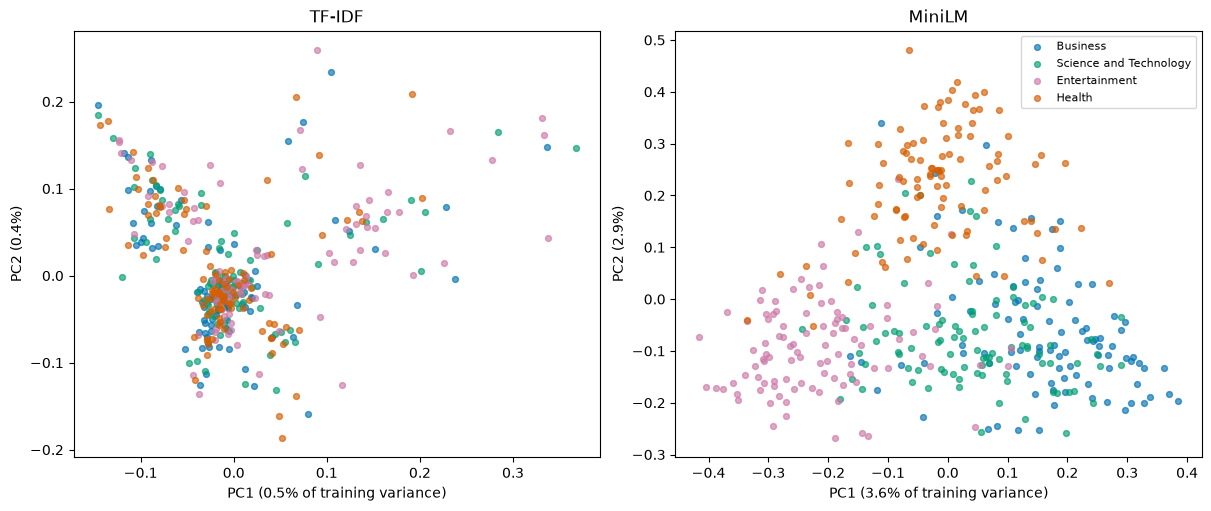

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5), constrained_layout=True)
palette = {"Business": "#0072B2", "Science and Technology": "#009E73",
           "Entertainment": "#CC79A7", "Health": "#D55E00"}
for ax, (method, make_vectors) in zip(axes, [("TF-IDF", tfidf_vectors),
                                             ("MiniLM", sentence_vectors)]):
    ref_vectors, query_vectors = make_vectors(train, test)
    pca = PCA(n_components=2, svd_solver="arpack", random_state=SEED)
    pca.fit(ref_vectors)
    xy = pca.transform(query_vectors)
    for topic, colour in palette.items():
        mask = labels[test] == topic
        ax.scatter(xy[mask, 0], xy[mask, 1], label=topic, color=colour, s=18, alpha=0.65)
    ax.set_title(method)
    ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%} of training variance)")
    ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%})")
axes[1].legend(fontsize=8)
fig.savefig(results / "pca_comparison.png", dpi=180)
plt.show()

## 8. Review at least ten real mistakes
Select ten distinct misclassified headlines across the two methods. Use held-out mistakes first and supplement with labelled out-of-fold mistakes only if needed. Read each headline and its neighbour. In the explanation column, record the words or ambiguity that may explain the prediction. Re-running preserves notes for the same cases.

In [9]:
errors = pd.concat([test_predictions, cv_predictions], ignore_index=True)
errors = errors.loc[errors.actual != errors.predicted]
test_errors = errors[errors.stage == "held-out test"].sample(frac=1, random_state=SEED)
cv_errors = errors[errors.stage != "held-out test"].sample(frac=1, random_state=SEED)
review = pd.concat([test_errors, cv_errors]).drop_duplicates("headline").head(10).copy()
review_file = results / "error_analysis.csv"
keys = ["method", "stage", "headline", "nearest_training_headline"]
if review_file.exists():
    notes = pd.read_csv(review_file, keep_default_na=False)
    review = review.merge(notes[keys + ["explanation"]], on=keys, how="left", validate="one_to_one")
else:
    review["explanation"] = ""
review.to_csv(review_file, index=False)
with pd.option_context("display.max_colwidth", 100):
    display(review[["method", "stage", "headline", "actual", "predicted", "nearest_training_headline"]])
print(f"{len(review)} distinct mistakes available for written review.")

,method,stage,headline,actual,predicted,nearest_training_headline
0,MiniLM,held-out test,Shigeru Ban Named Pritzker Laureate 2014,Entertainment,Health,Germ-killing ingredient banned
1,TF-IDF,held-out test,HP to invest over $1-billion in open-source cloud computing,Science and Technology,Business,HP settlement still needs court approval
2,TF-IDF,held-out test,MakerBot Enters Reselling Agreement with Panama Anantek,Science and Technology,Business,"Argentina fails to reach debt agreement, default imminent"
3,TF-IDF,held-out test,Earth struck by powerful asteroids at least twice a year,Science and Technology,Business,Alibaba isn't going global—at least not yet
4,MiniLM,held-out test,NBCU CEO Steve Burke: Jay Leno or Tina Fey Contractually Free to Go to CBS ...,Entertainment,Business,"CBS Profit Up On Higher Licensing, Pay TV Revenue"
5,TF-IDF,held-out test,"US Factories Expand, Construction Spending Inches Up",Business,Science and Technology,Spotify tipped to expand presence with carrier partnership
6,TF-IDF,held-out test,BLOGS OF THE DAY: Robin Williams to return as 'Mrs Doubtfire',Entertainment,Science and Technology,The Talker: 'Cosmos' makes its return
7,TF-IDF,held-out test,Audi to also offer Apple's CarPlay on its models,Science and Technology,Business,Audi Expects To Sell Half Million Cars In China This Year
8,TF-IDF,held-out test,BBM Chats Just Got More Fun with the Introduction of Stickers,Science and Technology,Entertainment,Fun with fireworks
9,MiniLM,held-out test,LGBT concerns grow as Brunei implements Sharia law,Entertainment,Health,Why Focus On LGBT Issues When That Affects Less Than 3 Percent Of ...


10 distinct mistakes available for written review.


,method,stage,accuracy,macro_f1
10,TF-IDF,held-out test,0.64750,0.648616
11,MiniLM,held-out test,0.83250,0.832601
12,MiniLM,CV mean,0.81625,0.815415
13,TF-IDF,CV mean,0.63875,0.639414


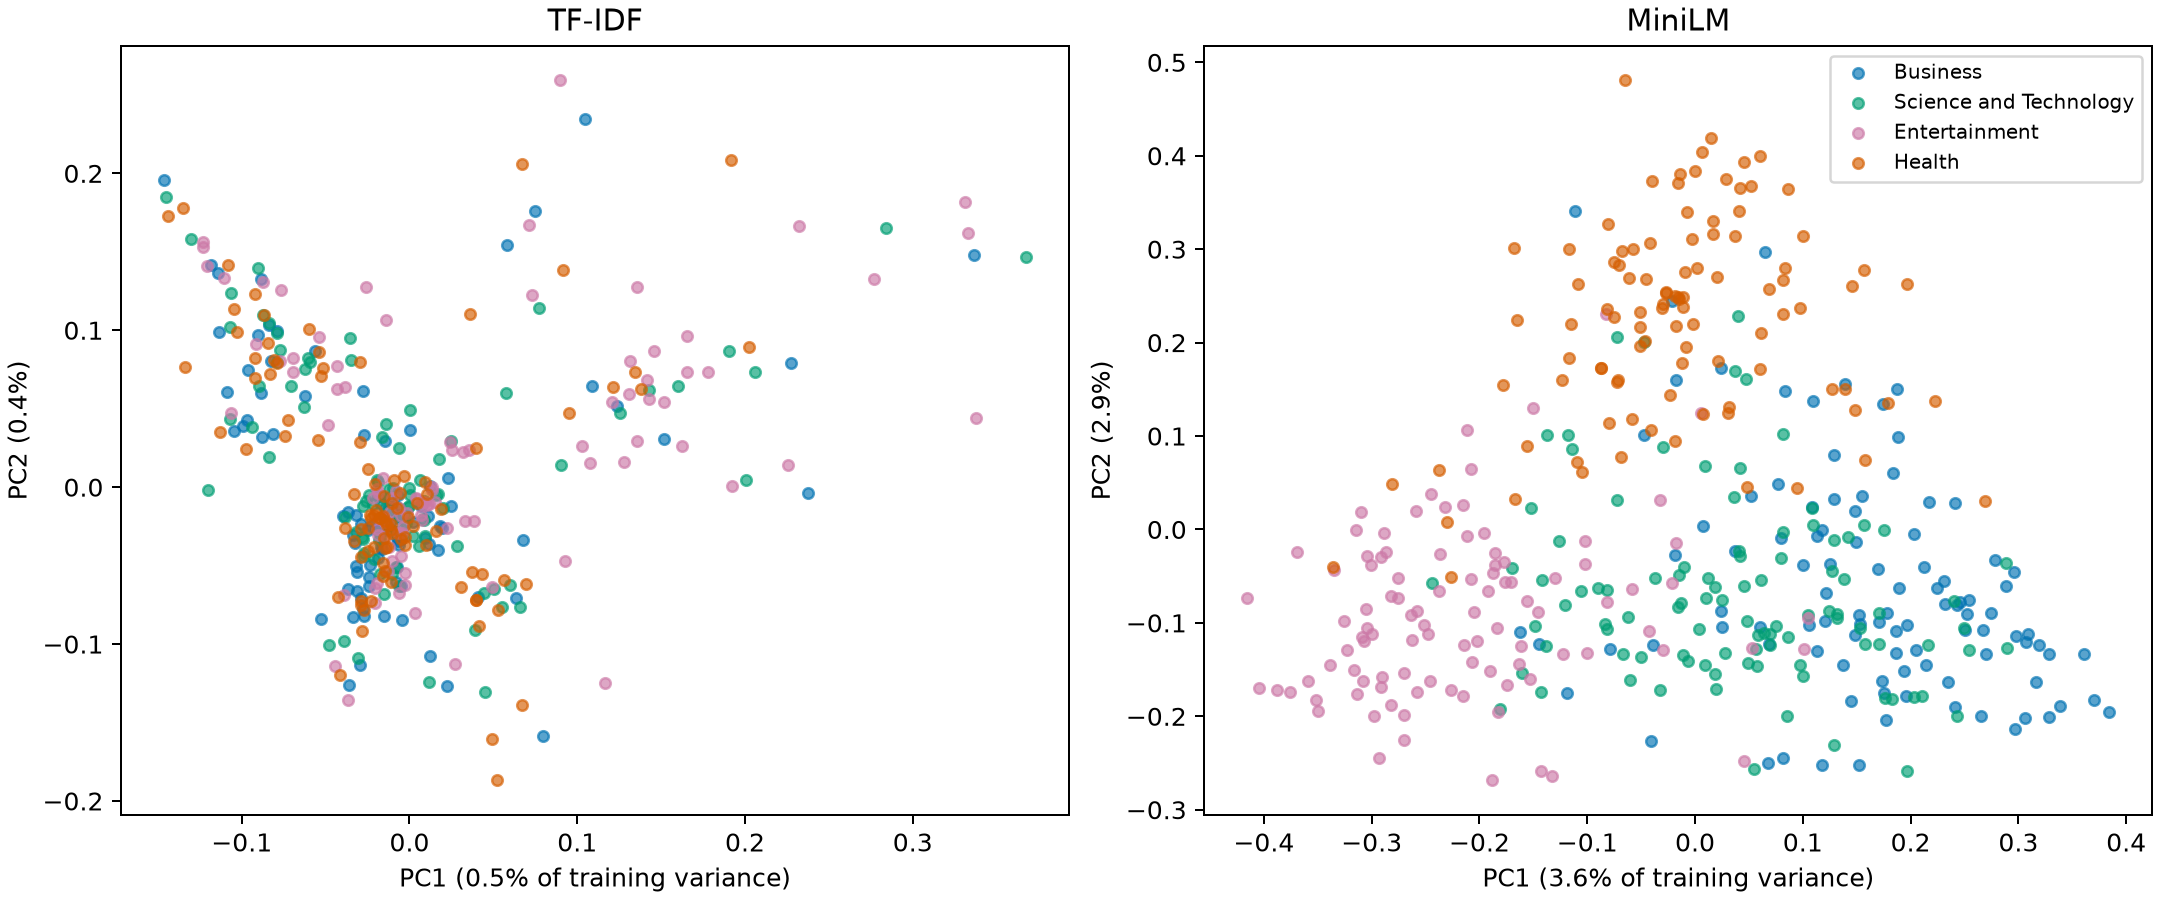

,headline,actual,predicted,explanation
0,Shigeru Ban Named Pritzker Laureate 2014,Entertainment,Health,
1,HP to invest over $1-billion in open-source cl...,Science and Technology,Business,
2,MakerBot Enters Reselling Agreement with Panam...,Science and Technology,Business,
3,Earth struck by powerful asteroids at least tw...,Science and Technology,Business,
4,NBCU CEO Steve Burke: Jay Leno or Tina Fey Con...,Entertainment,Business,
5,"US Factories Expand, Construction Spending Inc...",Business,Science and Technology,
6,BLOGS OF THE DAY: Robin Williams to return as ...,Entertainment,Science and Technology,
7,Audi to also offer Apple's CarPlay on its models,Science and Technology,Business,
8,BBM Chats Just Got More Fun with the Introduct...,Science and Technology,Entertainment,
9,LGBT concerns grow as Brunei implements Sharia...,Entertainment,Health,


In [10]:
from IPython.display import display, Image

# Show the scores calculated during this notebook run
display(report.loc[report["stage"].isin(["CV mean", "held-out test"])])

# Show the saved PCA plot
display(Image(filename="results/pca_comparison.png"))

# Check the ten mistakes and their written explanations
display(review[["headline", "actual", "predicted", "explanation"]])